### Homework: going neural (6 pts)

We've checked out statistical approaches to language models in the last notebook. Now let's go find out what deep learning has to offer.

<img src='https://raw.githubusercontent.com/yandexdataschool/nlp_course/master/resources/expanding_mind_lm_kn_3.png' width=300px>

We're gonna use the same dataset as before, except this time we build a language model that's character-level, not word level. Before you go:
* If you haven't done seminar already, use `seminar.ipynb` to download the data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Working on character level means that we don't need to deal with large vocabulary or missing words. Heck, we can even keep uppercase words in text! The downside, however, is that all our sequences just got a lot longer.

However, we still need special tokens:
* Begin Of Sequence  (__BOS__) - this token is at the start of each sequence. We use it so that we always have non-empty input to our neural network. $P(x_t) = P(x_1 | BOS)$
* End Of Sequence (__EOS__) - you guess it... this token is at the end of each sequence. The catch is that it should __not__ occur anywhere else except at the very end. If our model produces this token, the sequence is over.


In [2]:
!wget "https://www.dropbox.com/s/99az9n1b57qkd9j/arxivData.json.tar.gz?dl=1" -O arxivData.json.tar.gz
!tar -xvzf arxivData.json.tar.gz
data = pd.read_json("./arxivData.json")
data.sample(n=5)

--2026-10-10 08:17:48--  https://www.dropbox.com/s/99az9n1b57qkd9j/arxivData.json.tar.gz?dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.2.18, 2620:100:6017:18::a27d:212
Connecting to www.dropbox.com (www.dropbox.com)|162.125.2.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.dropbox.com/scl/fi/0mulrothty5o8i8ud9gz2/arxivData.json.tar.gz?rlkey=n759u5qx2xpxxglmrl390vwvk&dl=1 [following]
--2026-10-10 08:17:48--  https://www.dropbox.com/scl/fi/0mulrothty5o8i8ud9gz2/arxivData.json.tar.gz?rlkey=n759u5qx2xpxxglmrl390vwvk&dl=1
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://ucfb4c42544c9fc681bb15b2a883.dl.dropboxusercontent.com/cd/0/inline/DJseiaQGURBNYmmlas7PUy_TaSgAHgQeDYxuozmLYvNSayCPtPxy_NhH6UB0wAT5Y_6PRRFl0qLNL06eee86Gv7LVTZ3GKzRzFxH0CKa-KWB_yxyXYI9rOhr7vrla46piTs/file?dl=1# [following]
--2026-10-10 08:17:49--  https://ucfb4c42544c9fc681bb15b2a883.dl.dropboxuse

,author,day,id,link,month,summary,tag,title,year
6480,"[{'name': 'Nir Levine'}, {'name': 'Koby Cramme...",23,1702.07274v4,"[{'rel': 'alternate', 'href': 'http://arxiv.or...",2,The Multi-Armed Bandits (MAB) framework highli...,"[{'term': 'stat.ML', 'scheme': 'http://arxiv.o...",Rotting Bandits,2017
18482,"[{'name': 'Olusoji Okunoye'}, {'name': 'Bolanl...",15,1012.3336v1,"[{'rel': 'alternate', 'href': 'http://arxiv.or...",12,The shift from industrial economy to knowledge...,"[{'term': 'cs.AI', 'scheme': 'http://arxiv.org...",Dynamic Knowledge Capitalization through Annot...,2010
20339,[{'name': 'Muhammad Fahad'}],6,1510.01659v1,"[{'rel': 'alternate', 'href': 'http://arxiv.or...",10,"In this paper, we present the results obtained...","[{'term': 'cs.AI', 'scheme': 'http://arxiv.org...",DKP-AOM: results for OAEI 2015,2015
2983,"[{'name': 'Zhouhan Lin'}, {'name': 'Yushi Chen...",9,1511.02916v1,"[{'rel': 'related', 'href': 'http://dx.doi.org...",11,Hyperspectral image (HSI) classification is a ...,"[{'term': 'cs.CV', 'scheme': 'http://arxiv.org...",Spectral-Spatial Classification of Hyperspectr...,2015
32380,"[{'name': 'Khaled Fawagreh'}, {'name': 'Mohama...",17,1503.05187v1,"[{'rel': 'alternate', 'href': 'http://arxiv.or...",3,Random Forest (RF) is an ensemble classificati...,"[{'term': 'cs.LG', 'scheme': 'http://arxiv.org...",An Outlier Detection-based Tree Selection Appr...,2015


In [3]:
BOS, EOS = ' ', '\n'

data = pd.read_json("./arxivData.json")
lines = data.apply(lambda row: (row['title'] + ' ; ' + row['summary'])[:512], axis=1) \
            .apply(lambda line: BOS + line.replace(EOS, ' ') + EOS) \
            .tolist()

# if you missed the seminar, download data here - https://yadi.sk/d/_nGyU2IajjR9-w

Our next step is __building char-level vocabulary__. Put simply, you need to assemble a list of all unique tokens in the dataset.

In [4]:
# get all unique characters from lines (including capital letters and symbols)
tokens = list(set(ch for line in lines for ch in line))

tokens = sorted(tokens)
n_tokens = len(tokens)
print('n_tokens = ', n_tokens)
assert 100 < n_tokens < 150
assert BOS in tokens, EOS in tokens

n_tokens =  136


We can now assign each character with its index in tokens list. This way we can encode a string into a torch-friendly integer vector.

In [5]:
# dictionary of character -> its identifier (index in tokens list)
token_to_id = {ch: i for i, ch in enumerate(tokens)}

In [6]:
assert len(tokens) == len(token_to_id), "dictionaries must have same size"
for i in range(n_tokens):
    assert token_to_id[tokens[i]
                       ] == i, "token identifier must be it's position in tokens list"

print("Seems alright!")

Seems alright!


Our final step is to assemble several strings in a integer matrix with shape `[batch_size, text_length]`. 

The only problem is that each sequence has a different length. We can work around that by padding short sequences with extra `"EOS"` tokens or cropping long sequences. Here's how it works:

In [7]:
def to_matrix(lines, max_len=None, pad=token_to_id[EOS], dtype=np.int64):
    """Casts a list of lines into torch-digestable matrix"""
    max_len = max_len or max(map(len, lines))
    lines_ix = np.full([len(lines), max_len], pad, dtype=dtype)
    for i in range(len(lines)):
        line_ix = list(map(token_to_id.get, lines[i][:max_len]))
        lines_ix[i, :len(line_ix)] = line_ix
    return lines_ix

In [8]:
# Example: cast 4 random names to a single matrix, pad with zeros where needed.
dummy_lines = [
    ' abc\n',
    ' abacaba\n',
    ' abc1234567890\n',
]
print(to_matrix(dummy_lines))

[[ 1 66 67 68  0  0  0  0  0  0  0  0  0  0  0]
 [ 1 66 67 66 68 66 67 66  0  0  0  0  0  0  0]
 [ 1 66 67 68 18 19 20 21 22 23 24 25 26 17  0]]


### Neural Language Model (2 points including training)

Just like for N-gram LMs, we want to estimate probability of text as a joint probability of tokens (symbols this time).

$$P(X) = \prod_t P(x_t \mid x_0, \dots, x_{t-1}).$$

Instead of counting all possible statistics, we want to train a neural network with parameters $\theta$ that estimates the conditional probabilities:

$$ P(x_t \mid x_0, \dots, x_{t-1}) \approx p(x_t \mid x_0, \dots, x_{t-1}, \theta) $$


But before we optimize, we need to define our neural network. Let's start with a fixed-window (aka convolutional) architecture:

<img src='https://raw.githubusercontent.com/yandexdataschool/nlp_course/master/resources/fixed_window_lm.jpg' width=400px>


In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [10]:
device = 'cuda'

In [11]:
class FixedWindowLanguageModel(nn.Module):
    def __init__(self, n_tokens=n_tokens, emb_size=16, hid_size=64):
        """
        A fixed window model that looks on at least 5 previous symbols.

        Note: fixed window LM is effectively performing a convolution over a sequence of words.
        This convolution only looks on current and previous words.
        Such convolution can be represented as a sequence of 2 operations:
        - pad input vectors by {filter_size - 1} zero vectors on the "left", do not pad right
        - perform regular convolution with {filter_size} and stride 1

        - If you're absolutely lost, here's a hint: use nn.ZeroPad2d((NUM_LEADING_ZEROS, 0, 0, 0))
          followed by a nn.Conv1d(..., padding=0). And yes, its okay that padding is technically "2d".

        Feel free to try different window and model sizes to find configuration you'll like.
        """
        super().__init__()  # initialize base class to track sub-layers, trainable variables, etc.

        # YOUR CODE - create layers/variables and any metadata you want, e.g. self.emb = L.Embedding(...)

        self.filter_size = 5
        self.embeddings = nn.Embedding(
            num_embeddings=n_tokens, embedding_dim=emb_size)
        self.padding = nn.ZeroPad2d((self.filter_size - 1, 0, 0, 0))
        self.conv = nn.Conv1d(in_channels=emb_size,
                              out_channels=hid_size, kernel_size=5)
        self.head = nn.Linear(hid_size, n_tokens)

        # END OF YOUR CODE

    def __call__(self, input_ix):
        """
        compute language model logits given input tokens
        :param input_ix: batch of sequences with token indices, tensor: int32[batch_size, sequence_length]
        :returns: pre-softmax linear outputs of language model [batch_size, sequence_length, n_tokens]
            these outputs will be used as logits to compute P(x_t | x_0, ..., x_{t - 1})

        :note: that convolutions operate with tensors of shape [batch, channels, length], while linear layers
         and *embeddings* use [batch, length, channels] tensors. Use tensor.permute(...) to adjust shapes.

        """
        # YOUR CODE - apply layers, see docstring above
        x = self.embeddings(input_ix)
        x = x.transpose(-2, -1)
        x = self.padding(x)
        x = self.conv(x).transpose(-2, -1)
        logits = self.head(x)  # (batch, seq_len, n_tokens)

        # output tensor should be of shape [batch_size, sequence_length, n_tokens]
        return logits

    def get_possible_next_tokens(self, prefix=BOS, temperature=1.0, max_len=100):
        """ :returns: probabilities of next token, dict {token : prob} for all tokens """
        prefix_ix = torch.as_tensor(
            to_matrix([prefix]), dtype=torch.int64).to(device)
        with torch.no_grad():
            # shape: [n_tokens]
            probs = torch.softmax(self(prefix_ix)[0, -1], dim=-1).cpu().numpy()
        return dict(zip(tokens, probs))

In [12]:
dummy_model = FixedWindowLanguageModel().to(device)

dummy_input_ix = torch.as_tensor(to_matrix(dummy_lines)).to(device)
dummy_logits = dummy_model(dummy_input_ix)

print('Weights:', tuple(name for name, w in dummy_model.named_parameters()))

Weights: ('embeddings.weight', 'conv.weight', 'conv.bias', 'head.weight', 'head.bias')


In [13]:
assert isinstance(dummy_logits, torch.Tensor)
assert dummy_logits.shape == (len(dummy_lines), max(
    map(len, dummy_lines)), n_tokens), "please check output shape"
assert np.all(np.isfinite(dummy_logits.data.cpu().numpy())
              ), "inf/nan encountered"
assert not np.allclose(dummy_logits.data.cpu().numpy(
).sum(-1), 1), "please predict linear outputs, don't use softmax (maybe you've just got unlucky)"

In [14]:
# test for lookahead
dummy_input_ix_2 = torch.as_tensor(
    to_matrix([line[:3] + 'e' * (len(line) - 3) for line in dummy_lines])).to(device)
dummy_logits_2 = dummy_model(dummy_input_ix_2)

assert torch.allclose(dummy_logits[:, :3], dummy_logits_2[:, :3]), "your model's predictions depend on FUTURE tokens. " \
    " Make sure you don't allow any layers to look ahead of current token." \
    " You can also get this error if your model is not deterministic (e.g. dropout). Disable it for this test."

We can now tune our network's parameters to minimize categorical crossentropy over training dataset $D$:

$$ L = {\frac1{|D|}} \sum_{X \in D} \sum_{x_i \in X} - \log p(x_t \mid x_1, \dots, x_{t-1}, \theta) $$

As usual with with neural nets, this optimization is performed via stochastic gradient descent with backprop.  One can also note that minimizing crossentropy is equivalent to minimizing model __perplexity__, KL-divergence or maximizng log-likelihood.

In [15]:
def compute_mask(input_ix, eos_ix=token_to_id[EOS]):
    """ compute a boolean mask that equals "1" until first EOS (including that EOS) """
    return F.pad(torch.cumsum(input_ix == eos_ix, dim=-1)[..., :-1] < 1, pad=(1, 0, 0, 0), value=True)


print('matrix:\n', dummy_input_ix.cpu().numpy())
print('mask:', compute_mask(dummy_input_ix).to(torch.int32).cpu().numpy())
print('lengths:', compute_mask(dummy_input_ix).sum(-1).cpu().numpy())

matrix:
 [[ 1 66 67 68  0  0  0  0  0  0  0  0  0  0  0]
 [ 1 66 67 66 68 66 67 66  0  0  0  0  0  0  0]
 [ 1 66 67 68 18 19 20 21 22 23 24 25 26 17  0]]
mask: [[1 1 1 1 1 0 0 0 0 0 0 0 0 0 0]
 [1 1 1 1 1 1 1 1 1 0 0 0 0 0 0]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]]
lengths: [ 5  9 15]


In [16]:
def compute_loss(model, input_ix):
    """
    :param model: language model that can compute next token logits given token indices
    :param input ix: int32 matrix of tokens, shape: [batch_size, length]; padded with eos_ix
    :returns: scalar loss function, mean crossentropy over non-eos tokens
    """
    input_ix = torch.as_tensor(input_ix, dtype=torch.int64).to(device)

    logits = model(input_ix[:, :-1])
    reference_answers = input_ix[:, 1:]

    # Your task: implement loss function as per formula above
    # your loss should only be computed on actual tokens, excluding padding
    # predicting actual tokens and first EOS do count. Subsequent EOS-es don't
    # you may or may not want to use the compute_mask function from above.
    mask = compute_mask(input_ix)
    L = mask.sum()
    logits = F.log_softmax(logits, dim=-1)
    loss = -logits.gather(dim=2,
                          index=reference_answers[:, :, None]).squeeze(-1)
    loss = (loss * mask[:, 1:]).sum() / L
    return loss

In [17]:
loss_1 = compute_loss(dummy_model, to_matrix(dummy_lines, max_len=15))
loss_2 = compute_loss(dummy_model, to_matrix(dummy_lines, max_len=16))
assert (np.ndim(loss_1) == 0) and (
    0 < loss_1 < 100), "loss must be a positive scalar"
assert torch.allclose(loss_1, loss_2), 'do not include padding EOS tokens AFTER the first EOS into loss. '\
    'Hint: use compute_mask. Beware +/-1 errors. And be careful when averaging!'

### Evaluation

You will need two functions: one to compute test loss and another to generate samples. For your convenience, we implemented them both in your stead.

In [18]:
def score_lines(model, dev_lines, batch_size):
    """ computes average loss over the entire dataset """
    dev_loss_num, dev_loss_len = 0., 0.
    with torch.no_grad():
        for i in range(0, len(dev_lines), batch_size):
            batch_ix = to_matrix(dev_lines[i: i + batch_size])
            dev_loss_num += compute_loss(model,
                                         batch_ix).item() * len(batch_ix)
            dev_loss_len += len(batch_ix)
    return dev_loss_num / dev_loss_len


def generate(model, prefix=BOS, temperature=1.0, max_len=100):
    """
    Samples output sequence from probability distribution obtained by model
    :param temperature: samples proportionally to model probabilities ^ temperature
        if temperature == 0, always takes most likely token. Break ties arbitrarily.
    """
    with torch.no_grad():
        while True:
            token_probs = model.get_possible_next_tokens(prefix)
            tokens, probs = zip(*token_probs.items())
            if temperature == 0:
                next_token = tokens[np.argmax(probs)]
            else:
                probs = np.array([p ** (1. / temperature) for p in probs])
                probs /= sum(probs)
                next_token = np.random.choice(tokens, p=probs)

            prefix += next_token
            if next_token == EOS or len(prefix) > max_len:
                break
    return prefix

### Training loop

Finally, let's train our model on minibatches of data

In [19]:
from sklearn.model_selection import train_test_split
train_lines, dev_lines = train_test_split(
    lines, test_size=0.25, random_state=42)

batch_size = 256
score_dev_every = 250
train_history, dev_history = [], []
model = FixedWindowLanguageModel().to(device)
opt = torch.optim.Adam(model.parameters())

# hint: if you ever wanted to switch to cuda, do it now.

# score untrained model
dev_history.append((0, score_lines(model, dev_lines, batch_size)))
print("Sample before training:", generate(model, 'Bridging'))

Sample before training: BridgingH6çJ@Tvγ}T(Q%ôt)dŁB$Πü:;UgÜKΣduε1ãPló4°g5)-ŁS[zZõ



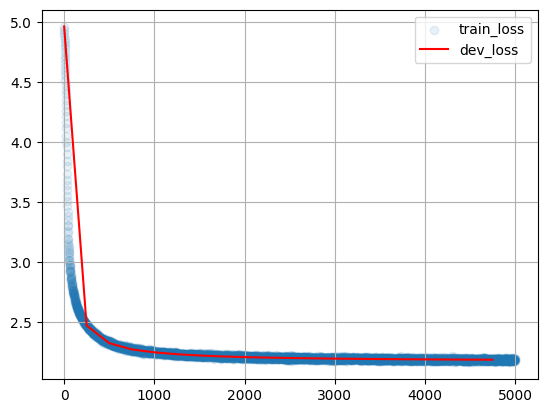

Generated examples (tau=0.5):
 Detion that on the s appremand ane verection seral work there thes and an we phoul oracinity as on t
 Alarization the seares ferelentricl areer sighe ther cone prevelude f ale rowe cher the vederations 
 A thin the rralgreat on lugens as and and of the perection the se the parien se fore the manelity fo
Scoring dev...


100%|██████████| 5000/5000 [02:47<00:00, 29.93it/s]

#4999 Dev loss: 2.184


In [23]:
from IPython.display import clear_output
from random import sample
from tqdm import trange

for i in trange(len(train_history), 5000):
    batch = to_matrix(sample(train_lines, batch_size))

    loss_i = compute_loss(model, batch)

    opt.zero_grad()
    loss_i.backward()
    opt.step()

    train_history.append((i, loss_i.item()))

    if (i + 1) % 50 == 0:
        clear_output(True)
        plt.scatter(*zip(*train_history), alpha=0.1, label='train_loss')
        if len(dev_history):
            plt.plot(*zip(*dev_history), color='red', label='dev_loss')
        plt.legend()
        plt.grid()
        plt.show()
        print("Generated examples (tau=0.5):")
        for _ in range(3):
            print(generate(model, temperature=0.5))

    if (i + 1) % score_dev_every == 0:
        print("Scoring dev...")
        dev_history.append((i, score_lines(model, dev_lines, batch_size)))
        print('#%i Dev loss: %.3f' % dev_history[-1])

In [24]:
assert np.mean(train_history[:10], axis=0)[1] > np.mean(
    train_history[-10:], axis=0)[1], "The model didn't converge."
print("Final dev loss:", dev_history[-1][-1])

for i in range(10):
    print(generate(model, temperature=0.5))

Final dev loss: 2.1835114138068223
 A Romed the rith ar pestrancomstimang anown the urale the s ation andertion and arale propect or hes
 Matho Evereathe periction ar ing mogs the cation ing conto t at muse thes ve work rod thate tant on 
 A Constime fore ffer athe oral mous tion the constiming andibis the sed the formagning ing ark of am
 Convere timale sustrat on iof al weration sed int in mation the mathing ing and calionte te the work
 Learnis on ther profict of ing whth the rabien for this s malem the tark an al whe sof che recorst c
 The se tome al ores deas in al arerscons speraction the thow rathe thor charization the semand te ti
 Deng te tom texis omparian ly we dation if ection the de torke perof cheret on the and ate probling 
 Spare preach ares monk ares for an seduth erale sing alens ffree wita se porete tiog ; The sef ches 
 Pandereas inge the semplessing er ared and at on the fer antere for chise the romest on the of and t
 A poricalizela iong fer byeat on the for the p

__What the samples should look like.__ This model is character-level, so its output will read like
plausible character soup: word-like fragments, arXiv-ish punctuation and very little actual meaning.
That is the expected result rather than a sign of a bug -- judge the model by the convergence assert
above and by dev loss, not by whether the samples read well.

You will likely find the RNN in the next section noticeably better with the default settings, but the
comparison is not apples-to-apples: this model defaults to `hid_size=64` while the RNN defaults to
`hid_size=256`. If the gap bothers you, give the fixed-window model a comparable hidden size (and
perhaps a second convolution) before concluding that the architecture is to blame -- at matched
capacity the two are far closer than the defaults suggest.

### RNN Language Models (3 points including training)

Fixed-size architectures are reasonably good when capturing short-term dependencies, but their design prevents them from capturing any signal outside their window. We can mitigate this problem by using a __recurrent neural network__:

$$ h_0 = \vec 0 ; \quad h_{t+1} = RNN(x_t, h_t) $$

$$ p(x_t \mid x_0, \dots, x_{t-1}, \theta) = dense_{softmax}(h_{t-1}) $$

Such model processes one token at a time, left to right, and maintains a hidden state vector between them. Theoretically, it can learn arbitrarily long temporal dependencies given large enough hidden size.

<img src='https://raw.githubusercontent.com/yandexdataschool/nlp_course/master/resources/rnn_lm.jpg' width=480px>

In [20]:
class RNNLanguageModel(nn.Module):
    def __init__(self, n_tokens=n_tokens, emb_size=16, hid_size=256):
        """
        Build a recurrent language model.
        You are free to choose anything you want, but the recommended architecture is
        - token embeddings
        - one or more LSTM/GRU layers with hid size
        - linear layer to predict logits

        :note: if you use nn.RNN/GRU/LSTM, make sure you specify batch_first=True
         With batch_first, your model operates with tensors of shape [batch_size, sequence_length, num_units]
         Also, please read the docs carefully: they don't just return what you want them to return :)
        """
        super().__init__()  # initialize base class to track sub-layers, trainable variables, etc.

        # YOUR CODE - create layers/variables/etc

        self.embeddings = nn.Embedding(
            num_embeddings=n_tokens, embedding_dim=emb_size)
        self.rnn = nn.RNN(input_size=emb_size,
                          hidden_size=hid_size, num_layers=1, batch_first=True)
        self.head = nn.Linear(hid_size, n_tokens)

        # END OF YOUR CODE

    def __call__(self, input_ix):
        """
        compute language model logits given input tokens
        :param input_ix: batch of sequences with token indices, tensor: int32[batch_size, sequence_length]
        :returns: pre-softmax linear outputs of language model [batch_size, sequence_length, n_tokens]
            these outputs will be used as logits to compute P(x_t | x_0, ..., x_{t - 1})
        """
        # YOUR CODE - apply layers, see docstring above
        x = self.embeddings(input_ix)
        h, _ = self.rnn(x)  # (batch, seq_len, hid_size)
        logits = self.head(h)
        return logits
        # output tensor should be of shape [batch_size, sequence_length, n_tokens]

    def get_possible_next_tokens(self, prefix=BOS, temperature=1.0, max_len=100):
        """ :returns: probabilities of next token, dict {token : prob} for all tokens """
        prefix_ix = torch.as_tensor(
            to_matrix([prefix]), dtype=torch.int64).to(device)
        with torch.no_grad():
            # shape: [n_tokens]
            probs = torch.softmax(self(prefix_ix)[0, -1], dim=-1).cpu().numpy()
        return dict(zip(tokens, probs))

In [21]:
model = RNNLanguageModel().to(device)

dummy_input_ix = torch.as_tensor(to_matrix(dummy_lines)).to(device)
dummy_logits = model(dummy_input_ix)

assert isinstance(dummy_logits, torch.Tensor)
assert dummy_logits.shape == (len(dummy_lines), max(
    map(len, dummy_lines)), n_tokens), "please check output shape"
assert not np.allclose(dummy_logits.cpu().data.numpy(
).sum(-1), 1), "please predict linear outputs, don't use softmax (maybe you've just got unlucky)"
print('Weights:', tuple(name for name, w in model.named_parameters()))

Weights: ('embeddings.weight', 'rnn.weight_ih_l0', 'rnn.weight_hh_l0', 'rnn.bias_ih_l0', 'rnn.bias_hh_l0', 'head.weight', 'head.bias')


In [22]:
# test for lookahead
dummy_input_ix_2 = torch.as_tensor(
    to_matrix([line[:3] + 'e' * (len(line) - 3) for line in dummy_lines])).to(device)
dummy_logits_2 = model(dummy_input_ix_2)

assert torch.allclose(dummy_logits[:, :3], dummy_logits_2[:, :3]), "your model's predictions depend on FUTURE tokens. " \
    " Make sure you don't allow any layers to look ahead of current token." \
    " You can also get this error if your model is not deterministic (e.g. dropout). Disable it for this test."

### RNN training

Our RNN language model should optimize the same loss function as fixed-window model. But there's a catch. Since RNN recurrently multiplies gradients through many time-steps, gradient values may explode, [ruining](https://raw.githubusercontent.com/yandexdataschool/nlp_course/master/resources/nan.jpg) your model.
The common solution to that problem is to clip gradients either [by value](https://pytorch.org/docs/stable/generated/torch.nn.utils.clip_grad_value_.html) or [by global norm](https://pytorch.org/docs/stable/generated/torch.nn.utils.clip_grad_norm_.html).

Your task here is to implement the training code that minimizes the loss function. If you encounter large loss fluctuations during training, please add gradient clipping using the urls above -- call it after `loss_i.backward()` and before `opt.step()`. But its **not necessary** to use gradient clipping if you don't need it.

_Note: gradient clipping is not exclusive to RNNs. Convolutional networks with enough depth often suffer from the same issue._

In [23]:
batch_size = 128       # <-- please tune batch size to fit your CPU/GPU configuration
score_dev_every = 250
train_history, dev_history = [], []

model = RNNLanguageModel().to(device)
opt = torch.optim.Adam(model.parameters())

# score untrained model
dev_history.append((0, score_lines(model, dev_lines, batch_size)))
print("Sample before training:", generate(model, 'Bridging'))

Sample before training: BridgingyλiX-<æεVíãç4eæmêJd.dá69<3äνAΩ5qD9Ö+M\Y}O~~_Kéçá,6:d*kQa9Q\ä>kB,o*,ysA5X!)vvâBeμp)*:S30üÉé(L)


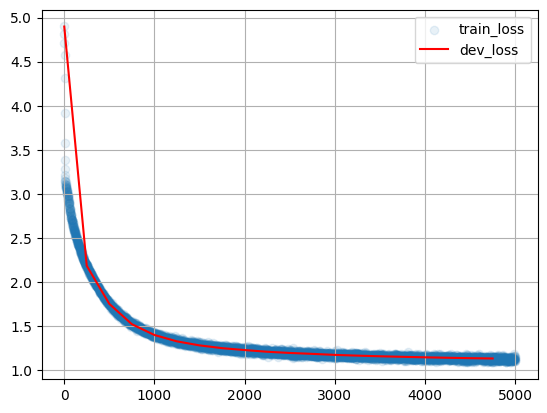

Gradient norm: 0.224
Generated examples (tau=0.5):
 To of which iterations of the statistical extraction (SCA) matrix from a success, which is the compu
 Learning Signal Semantic Exploiting Partial reasoning algorithm for real-world models have been deve
 Convolutional Neural Networks ; This paper proposes a new convolutional neural networks have been de
Scoring dev...


100%|██████████| 5000/5000 [03:38<00:00, 22.93it/s]

#4999 Dev loss: 1.128


In [24]:
from IPython.display import clear_output
from random import sample
from tqdm import trange

for i in trange(len(train_history), 5000):
    batch = to_matrix(sample(train_lines, batch_size))

    # <YOUR CODE - one step of the training loop for your RNN model>

    loss_i = compute_loss(model, batch)

    opt.zero_grad()
    loss_i.backward()
    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(), max_norm=1.0)
    opt.step()

    train_history.append((i, float(loss_i)))

    if (i + 1) % 50 == 0:
        clear_output(True)
        plt.scatter(*zip(*train_history), alpha=0.1, label='train_loss')
        if len(dev_history):
            plt.plot(*zip(*dev_history), color='red', label='dev_loss')
        plt.legend()
        plt.grid()
        plt.show()
        print(f"Gradient norm: {grad_norm:.3f}")
        print("Generated examples (tau=0.5):")
        for _ in range(3):
            print(generate(model, temperature=0.5))

    if (i + 1) % score_dev_every == 0:
        print("Scoring dev...")
        dev_history.append((i, score_lines(model, dev_lines, batch_size)))
        print('#%i Dev loss: %.3f' % dev_history[-1])

In [25]:
assert np.mean(train_history[:10], axis=0)[1] > np.mean(
    train_history[-10:], axis=0)[1], "The model didn't converge."
print("Final dev loss:", dev_history[-1][-1])
for i in range(10):
    print(generate(model, temperature=0.5))

Final dev loss: 1.127896173360871
 Semantic Selection ; This paper describe distribution of the challenge from an important inherent to
 Scalable Land Properties ; We propose a novel models from the best prediction of the different metho
 The Convex Hypath Problem Model ; In this work, we propose a new approach of the previous topic appr
 Clustering ; The fusing the structure of the algorithm for every a social method for models with eva
 Multi-Processers ; This paper interaction in the local image classification events deep neural netwo
 Convolutional Neural Networks (CNN) is a sentences are complex complex the problem of convex only in
 Recognition of Deep Neural Networks (CNN), which is the distribution of the interest in the stable m
 Language To Samples ; Since the generalization of the graph the models that are recent years, which 
 Learning the Markov processes and the set of the model bounds of the problem of previous works are u
 Experimental Functions ; The discovery of the m

### Alternative sampling strategies (1 point)

So far we've sampled tokens from the model in proportion with their probability.
However, this approach can sometimes generate nonsense words due to the fact that softmax probabilities of these words are never exactly zero. This issue can be somewhat mitigated with sampling temperature, but low temperature harms sampling diversity. Can we remove the nonsense words without sacrificing diversity? __Yes, we can!__ But it takes a different sampling strategy.

__Top-k sampling:__ on each step, sample the next token from __k most likely__ candidates from the language model.

Suppose $k=3$ and the token probabilities are $p=[0.1, 0.35, 0.05, 0.2, 0.3]$. You first need to select $k$ most likely words and set the probability of the rest to zero: $\hat p=[0.0, 0.35, 0.0, 0.2, 0.3]$ and re-normalize: 
$p^*\approx[0.0, 0.412, 0.0, 0.235, 0.353]$.

__Nucleus sampling:__ similar to top-k sampling, but this time we select $k$ dynamically. In nucleus sampling, we sample from top-__N%__ fraction of the probability mass.

Using the same  $p=[0.1, 0.35, 0.05, 0.2, 0.3]$ and nucleus N=0.9, the nucleus words consist of:
1. most likely token $w_2$, because $p(w_2) < N$
2. second most likely token $w_5$, $p(w_2) + p(w_5) = 0.65 < N$
3. third most likely token $w_4$ because $p(w_2) + p(w_5) + p(w_4) = 0.85 < N$

And thats it, because the next most likely word would overflow: $p(w_2) + p(w_5) + p(w_4) + p(w_1) = 0.95 > N$.

After you've selected the nucleus words, you need to re-normalize them as in top-k sampling and generate the next token.

__Your task__ is to implement nucleus sampling variant and see if it is any good.

In [26]:
def generate_nucleus(model, prefix=BOS, nucleus=0.9, max_len=100):
    r"""
    Generate a sequence with nucleus sampling
    :param prefix: a string of characters generated so far, which the model continues
    :param nucleus: N from the formulae above, N \in [0, 1]
    :param max_len: generate sequences with at most this many tokens, including prefix

    :note: make sure that nucleus always contains at least one word, even if p(w*) > nucleus

    """
    while True:
        token_probs = model.get_possible_next_tokens(prefix)
        tokens, probs = zip(*token_probs.items())
        probs = torch.tensor(probs)
        sort_probs = torch.sort(probs, descending=True)
        cum_probs = torch.cumsum(sort_probs.values, dim=0)
        zero_ind = sort_probs.indices[cum_probs > nucleus]
        zero_ind = zero_ind if len(zero_ind) < len(
            probs) else sort_probs.indices[1:]
        probs[zero_ind] = 0.0
        probs = probs / probs.sum()

        # <YOUR CODE HERE: restrict tokens to the nucleus, renormalize, then sample>

        probs = probs.cpu().numpy()

        next_token = np.random.choice(tokens, p=probs)
        prefix += next_token
        if next_token == EOS or len(prefix) > max_len:
            break
    return prefix

In [27]:
for i in range(10):
    print(generate_nucleus(model, nucleus=0.75))

 A Neural Networks ; We show that the results with the representation in computer vision models that 
 A Particle Divergence Networks ; We consider the representation and the target description of increa
 On Electroshetable Analysis for Segmentation ; Detecting a logic by the approach is a proposed for p
 Classification of Sparse Particle Control Model for Integration of Multi-Case ; The method based on 
 Learning Context Learning for Programming for Solver (LDA) is an individual models are applied to th
 Detection and Neural Networks ; This paper assumed to a local and more and classification methods in
 Learning ; We consider the research for entity decision of the low-dimensional and specific computat
 Convolutional Neural Networks (CNNs) is developed for deep learning in particular the training data 
 Markov description methods for reconstruction problem to provide many distributions and a different 
 A Regularized Similarity ; We introduce a new statistical and the large set of co

### Bonus quest I: Beam Search (2 pts incl. samples)

At times, you don't really want the model to generate diverse outputs as much as you want a __single most likely hypothesis.__ A single best translation, most likely continuation of the search query given prefix, etc. Except, you can't get it. 

In order to find the exact most likely sequence containing 10 tokens, you would need to enumerate all $|V|^{10}$ possible hypotheses. In practice, 9 times out of 10 you will instead find an approximate most likely output using __beam search__.

Here's how it works:
0. Initial `beam` = [prefix], max beam_size = k
1. for T steps:
2. ` ... ` generate all possible next tokens for all hypotheses in beam, formulate `len(beam) * len(vocab)` candidates
3. ` ... ` select beam_size best for all candidates as new `beam`
4. Select best hypothesis (-es?) from beam

In [ ]:
from IPython.display import HTML
# Here's what it looks like:
!wget -q https://raw.githubusercontent.com/yandexdataschool/nlp_course/2020/resources/beam_search.html
HTML("beam_search.html")

In [ ]:
def generate_beamsearch(model, prefix=BOS, beam_size=4, length=5):
    """
    Generate a sequence with beam search
    :param prefix: a string containing space-separated previous tokens
    :param beam_size: maintain this many top-k hypotheses in beam
    :param length: generate sequences with at most this many tokens, NOT INCLUDING PREFIX
    :returns: beam_size most likely candidates
    """

    beam = [prefix]
    beam_probs = torch.zeros(beam_size)
    for i in range(length):
        # print(f'{i=}')
        top_values = torch.tensor([-torch.inf] * beam_size)
        top_tok = [""] * beam_size
        for k, beam_prefix in enumerate(beam):
            if beam_prefix.endswith(EOS):
                cand_toks = [beam_prefix]
                cand_vals = beam_probs[k:k + 1]
            else:
                token_probs = model.get_possible_next_tokens(beam_prefix)
                tokens, probs = zip(*token_probs.items())
                probs = torch.log(torch.tensor(probs)) + beam_probs[k]
                sort_probs = torch.sort(probs, descending=True)
                cand_toks = [beam_prefix + tokens[j]
                             for j in sort_probs.indices[:beam_size]]
                cand_vals = sort_probs.values[:beam_size]

            for tok, val in zip(cand_toks, cand_vals):
                min_prob_ind = top_values.argmin()
                if val > top_values[min_prob_ind]:
                    top_values[min_prob_ind] = val
                    top_tok[min_prob_ind] = tok

        top_values_sort = torch.sort(top_values, descending=True)
        top_values = top_values_sort.values
        top_tok = [top_tok[i] for i in top_values_sort.indices]
        beam = top_tok
        beam_probs = top_values
        if all(t.endswith(EOS) for t in beam):
            break
    return beam

In [76]:
generate_beamsearch(model, prefix=' deep ', beam_size=4)

[' deep learn', ' deep neura', ' deep netwo', ' deep convo']

In [ ]:
# check it out: which beam size works best?
# find at least 5 prefixes where beam_size=1 and 8 generates different sequences
generate_beamsearch(model, prefix=' bridging the gap ',
                    beam_size=1, length=100)

[' bridging the gap recognition and the statistical models are computer vision problems in the statistical models are co']

### Bonus quest II: Ultimate Language Model (2+ pts)

So you've learned the building blocks of neural language models, you can now build the ultimate monster:  
* Make it char-level, word level or maybe use sub-word units like [bpe](https://github.com/rsennrich/subword-nmt);
* Combine convolutions, recurrent cells, pre-trained embeddings and all the black magic deep learning has to offer;
  * Use strides to get larger window size quickly. Here's a [scheme](https://storage.googleapis.com/deepmind-live-cms/documents/BlogPost-Fig2-Anim-160908-r01.gif) from google wavenet.
* Train on large data. Like... really large. Try [1 Billion Words](http://www.statmt.org/lm-benchmark/1-billion-word-language-modeling-benchmark-r13output.tar.gz) benchmark;
* Use training schedules to speed up training. Start with small length and increase over time; Take a look at [one cycle](https://medium.com/@nachiket.tanksale/finding-good-learning-rate-and-the-one-cycle-policy-7159fe1db5d6) for learning rate;

_You are NOT required to submit this assignment. Please make sure you don't miss your deadline because of it :)_